# Introduction to Machine Learning – Lab 2
## Bonus: LightGBM vs. XGBoost

### Objective
This notebook implements and tunes **LightGBM**, another gradient-boosted trees library, on exactly the same features as the XGBoost models of notebooks 02–05.1, and compares the two:
1. **How the trees are built:** depth-wise (XGBoost) vs. leaf-wise (LightGBM) growth, with tree plots and the shape of all trees in the ensemble.
2. **The learning process:** learning curves with early stopping, number of rounds, training time and feature importance.
3. **The results:** default models, a short manual tuning, Bayesian optimization with Optuna (`TPESampler`), and a final comparison on all 70 splits, each **with and without SMOTE**.

**Same setup as for XGBoost:** the same 2,925 houses with 72 features, the same one-hot encoding of the nominal features (fitted on the training part only), the same 70 splits of notebooks 02–05.1 and, for the SMOTE models, the same SMOTE step on the training part (`build_pipeline(..., smote=True, model=...)`). The XGBoost reference models are recomputed on the same splits:
* the default XGBoost model (notebook 02), with and without SMOTE
* the tuned XGBoost model of notebook 05 (best Optuna trial, no SMOTE)
* the best XGBoost model with SMOTE of notebook 05.1 (manual combination)

In [1]:
import sys
import time
import warnings
from pathlib import Path

# Add project root and notebooks/ to system path
sys.path.append(str(Path(".").resolve()))
sys.path.append(str(Path("notebooks").resolve()))

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
from lightgbm import LGBMClassifier
from optuna.pruners import MedianPruner
from optuna.samplers import TPESampler
from optuna.visualization import matplotlib as optuna_plots
from sklearn.base import clone
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from xgboost import plot_tree as xgb_plot_tree

from evaluation import evaluate, make_splits, summarize
from preprocessing import CLASS_NAMES, build_pipeline, make_preprocessor, prepare_data

sns.set_theme(style="whitegrid")
optuna.logging.set_verbosity(optuna.logging.WARNING)
# The matplotlib versions of the Optuna plots are marked as experimental
warnings.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning)

DATA_PATH = Path("../data/AmesHousing.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/AmesHousing.csv")

# Same data as notebooks 02–05.1
X, y = prepare_data(DATA_PATH, drop_extreme=True, drop_near_constant=True)
print(f"Dataset dimensions: X = {X.shape}, y = {y.shape}")

# All 70 splits of notebooks 02–05.1, and the 5 folds used for tuning
splits = make_splits(y)
cv5 = [split for split in splits if split["Setup"] == "CV k=5, stratified"]
num_classes = len(CLASS_NAMES)

# XGBoost defaults (the baseline of notebook 02) and the two tuned XGBoost reference models
XGB_DEFAULTS = {
    "max_depth": 6, "learning_rate": 0.3, "n_estimators": 100, "min_child_weight": 1, "subsample": 1.0,
    "colsample_bytree": 1.0, "reg_lambda": 1.0, "reg_alpha": 0.0, "gamma": 0.0,
}
STORAGE = "sqlite:///optuna_ames_housing.db"
# Best Optuna trial of notebook 05 (no SMOTE)
XGB_TUNED = optuna.load_study(study_name="xgboost_macro_f1_tpe", storage=STORAGE).best_params
# Manual combination of notebook 05.1, Section 1.8 (with SMOTE)
XGB_SMOTE_MANUAL = {
    "learning_rate": 0.05, "n_estimators": 600, "min_child_weight": 3.0,
    "subsample": 0.6, "colsample_bytree": 0.3, "reg_lambda": 5.0,
}


def make_xgb(smote=False, **params):
    """XGBoost pipeline of notebooks 05 / 05.1: one-hot encoding (+ SMOTE) and XGBoost."""
    return build_pipeline(
        "onehot", min_frequency=5, smote=smote, enable_categorical=False, tree_method="hist",
        **{**XGB_DEFAULTS, **params},
    )


def make_lgbm(smote=False, **params):
    """The same encoding (+ SMOTE), with a LightGBM classifier instead of XGBoost."""
    return build_pipeline(
        "onehot", min_frequency=5, smote=smote, model=LGBMClassifier(random_state=42, verbose=-1, **params)
    )


def cv_scores(model):
    """Mean scores over the 5 stratified folds; Gap = training minus test macro-F1 (variance)."""
    scores = evaluate(model, X, y, cv5)
    return {
        "Train Macro-F1": scores["Train Macro-F1"].mean(),
        "Test Macro-F1": scores["Test Macro-F1"].mean(),
        "Test Macro-F1 Std": scores["Test Macro-F1"].std(),
        "Test Accuracy": scores["Test Accuracy"].mean(),
        "Gap": scores["Train Macro-F1"].mean() - scores["Test Macro-F1"].mean(),
    }


def run_models(models):
    """Fit and score every model on all 70 splits; also return the mean time per fit (incl. prediction)."""
    results, seconds = [], {}
    for name, model in models.items():
        start = time.perf_counter()
        results.append(evaluate(model, X, y, splits).assign(Variant=name))
        seconds[name] = (time.perf_counter() - start) / len(splits)
    return pd.concat(results, ignore_index=True), pd.Series(seconds, name="Seconds per fit")


def paired(results, pairs):
    """Macro-F1 of model a minus macro-F1 of model b on the same split, for every pair (a, b)."""
    wide = results.pivot_table(index=["Setup", "Split"], columns="Variant", values="Test Macro-F1")
    experiment = wide.index.get_level_values("Setup").str.split().str[0]
    table = {}
    for a, b in pairs:
        diff = wide[a] - wide[b]
        groups = [*diff.groupby(experiment, sort=False), ("All 70 splits", diff)]
        table[f"{a} − {b}"] = {
            (name, stat): value
            for name, group in groups
            for stat, value in [("Mean Difference", group.mean()), ("Std", group.std()),
                                ("Better", (group > 0).sum()), ("Worse", (group < 0).sum())]
        }
    return pd.DataFrame(table).T.round(4)


def gap_table(results):
    """Training vs. test macro-F1, averaged over all 70 splits."""
    gap = results.groupby("Variant", sort=False)[["Train Macro-F1", "Test Macro-F1"]].mean()
    gap["Gap"] = gap["Train Macro-F1"] - gap["Test Macro-F1"]
    return gap.round(4)

Dataset dimensions: X = (2925, 72), y = (2925,)


### 1. How the trees are built
Both libraries are gradient boosting on histograms: the values of every feature are sorted into at most 256 (XGBoost, `tree_method="hist"`) or 255 (LightGBM) bins, and splits are only searched at the bin borders. For six classes, both fit one tree per class in every round, on the gradients and hessians of the softmax log-loss, and both score a split with the same gain formula with an L2 penalty $\lambda$ (notebook 05, Section 1). The main difference is the **order in which a tree is grown**:
* **XGBoost grows depth-wise (level by level).** All nodes of one level are split before the next level starts, as long as the gain is positive. `max_depth` (default 6) limits the tree to at most $2^6 = 64$ leaves, and no path is longer than `max_depth` splits.
* **LightGBM grows leaf-wise (best-first).** It always splits the one leaf, among all current leaves, whose best split has the highest gain. `num_leaves` (default 31) limits the number of leaves; the depth is not limited by default (`max_depth = -1`). With the same number of leaves, a leaf-wise tree can become deep and unbalanced: it keeps refining the region where the loss falls the most and leaves the other regions coarse. This lowers the training loss faster per leaf, but can also overfit faster on small data sets. That is why `min_child_samples` (default 20 houses per leaf) matters.
* **LightGBM's additional techniques:** *Exclusive Feature Bundling* (EFB, on by default) merges features that are never non-zero at the same time into one feature. This is exactly the case for the one-hot columns of one nominal feature, so fewer features have to be searched. *Gradient-based One-Side Sampling* (GOSS) keeps the houses with large gradients and samples among the others; it is optional and not used here (the default `gbdt` boosting uses all houses).

**Plots:** to compare the shapes directly, both libraries get the **same leaf budget of 8 leaves per tree**: XGBoost with `max_depth=3`, LightGBM with `num_leaves=8` and no depth limit. Both use `learning_rate=0.1` and early stopping on the same 20% stratified validation split as in notebook 03 (boosting stops when the validation log-loss has not improved for 20 rounds). The plots show the class-0 tree (`< 100k`) of the first round and of the best round.

XGBoost  (max_depth=3):  best round 282, validation log-loss 0.5641, 1.7 s for 303 rounds
LightGBM (num_leaves=8): best round 85, validation log-loss 0.5698, 0.2 s for 106 rounds


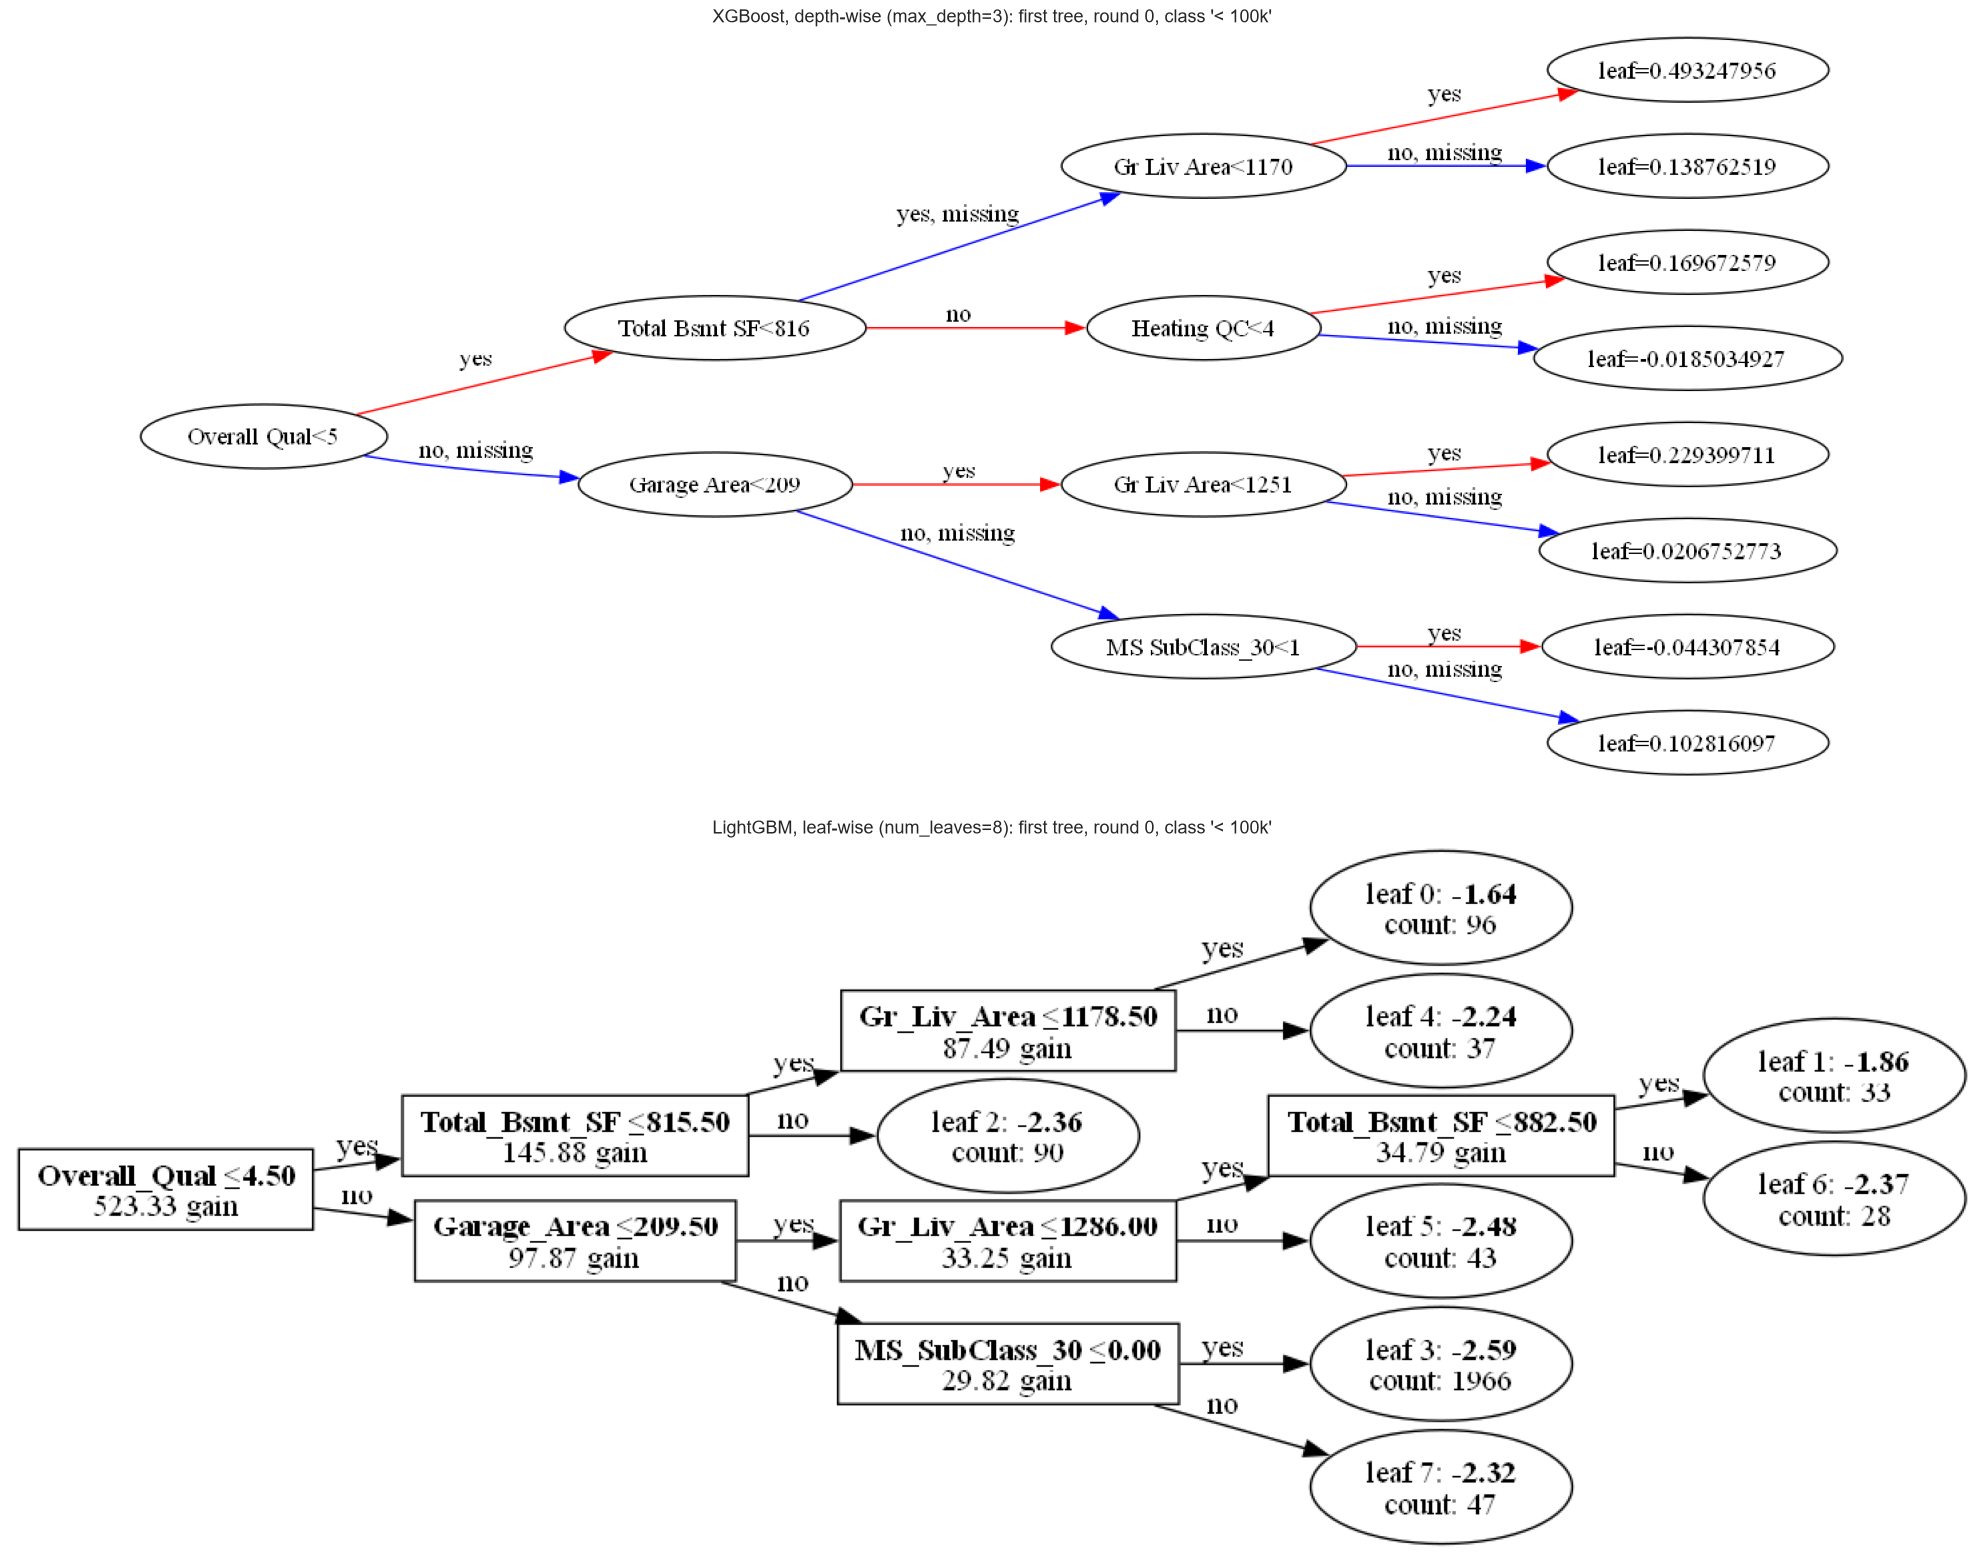

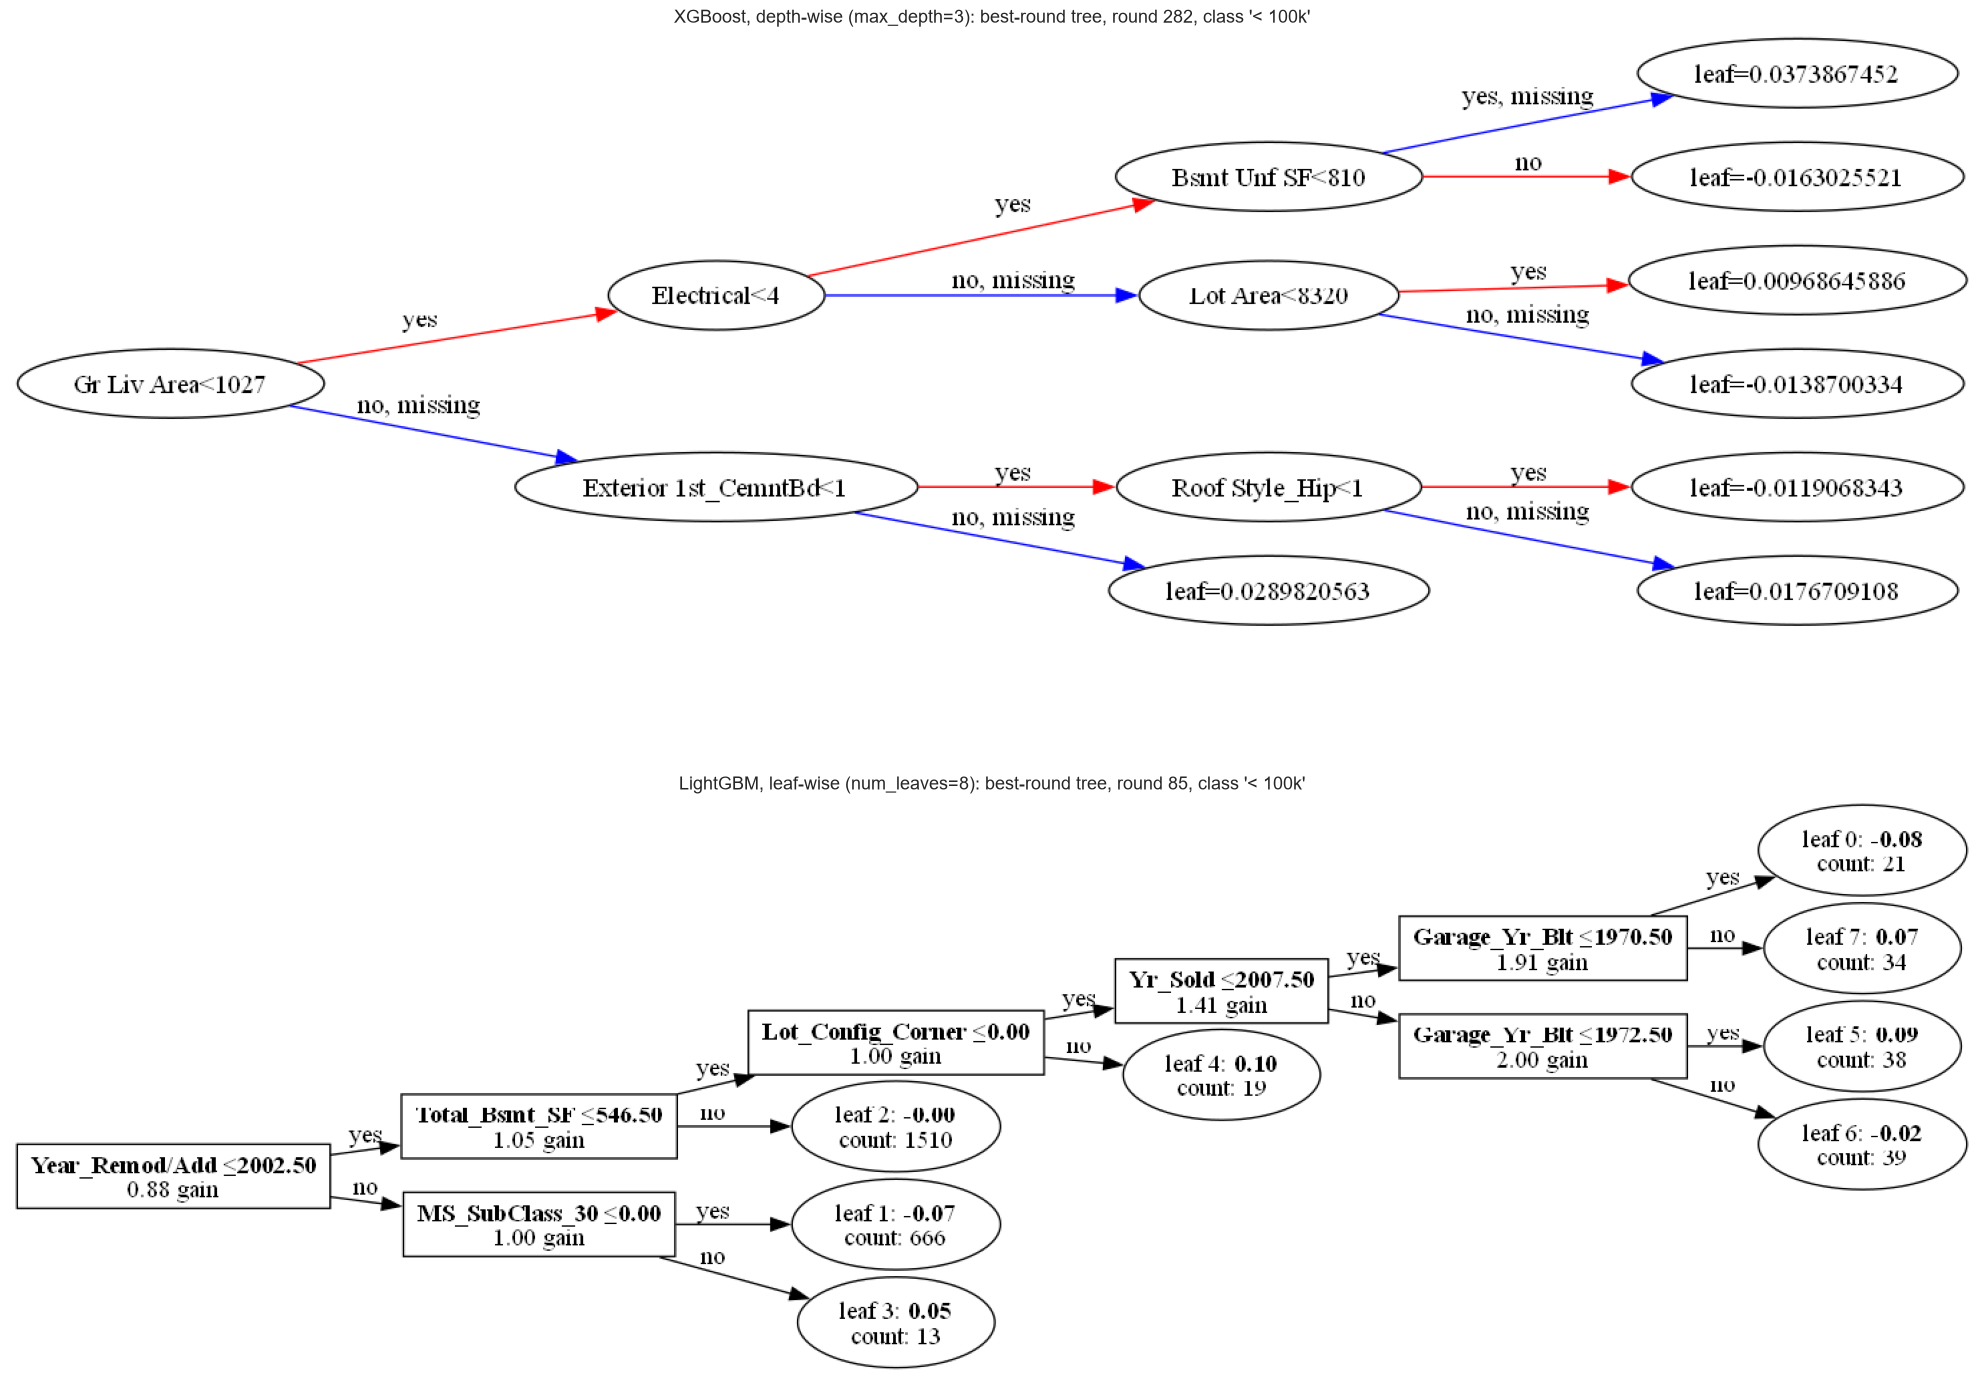

In [2]:
# 80/20 stratified split: the 20% validation houses decide when boosting stops (as in notebook 03)
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
prep = make_preprocessor("onehot", min_frequency=5)
X_train_enc = prep.fit_transform(X_train, y_train)
X_val_enc = prep.transform(X_val)

# Same leaf budget: XGBoost depth-wise with max_depth=3, LightGBM leaf-wise with num_leaves=8
xgb_small = XGBClassifier(
    n_estimators=1000, learning_rate=0.1, max_depth=3, eval_metric="mlogloss",
    early_stopping_rounds=20, tree_method="hist", random_state=42,
)
start = time.perf_counter()
xgb_small.fit(X_train_enc, y_train, eval_set=[(X_train_enc, y_train), (X_val_enc, y_val)], verbose=False)
xgb_seconds = time.perf_counter() - start

lgbm_small = LGBMClassifier(n_estimators=1000, learning_rate=0.1, num_leaves=8, random_state=42, verbose=-1)
start = time.perf_counter()
lgbm_small.fit(
    X_train_enc, y_train, eval_X=(X_train_enc, X_val_enc), eval_y=(y_train, y_val),
    eval_names=["training", "validation"], eval_metric="multi_logloss",
    callbacks=[lgb.early_stopping(20, verbose=False)],
)
lgbm_seconds = time.perf_counter() - start

# Best round, counted from 0 for both (LightGBM counts its iterations from 1)
best_xgb = xgb_small.best_iteration
best_lgbm = lgbm_small.best_iteration_ - 1
print(f"XGBoost  (max_depth=3):  best round {best_xgb}, validation log-loss {xgb_small.best_score:.4f}, "
      f"{xgb_seconds:.1f} s for {best_xgb + 21} rounds")
print(f"LightGBM (num_leaves=8): best round {best_lgbm}, validation log-loss "
      f"{lgbm_small.best_score_['validation']['multi_logloss']:.4f}, {lgbm_seconds:.1f} s for {best_lgbm + 21} rounds")


def show_trees(round_xgb, round_lgbm, label):
    """Class-0 tree of the given round for both libraries (tree index = round × 6 + class)."""
    fig, axes = plt.subplots(2, 1, figsize=(20, 16))
    xgb_plot_tree(xgb_small, tree_idx=round_xgb * num_classes, rankdir="LR", ax=axes[0])
    axes[0].set_title(f"XGBoost, depth-wise (max_depth=3): {label}, round {round_xgb}, class '{CLASS_NAMES[0]}'", fontsize=13)
    lgb.plot_tree(lgbm_small, tree_index=round_lgbm * num_classes, ax=axes[1], show_info=["split_gain", "leaf_count"], precision=2)
    axes[1].set_title(f"LightGBM, leaf-wise (num_leaves=8): {label}, round {round_lgbm}, class '{CLASS_NAMES[0]}'", fontsize=13)
    plt.tight_layout()
    plt.show()


show_trees(0, 0, "first tree")
show_trees(best_xgb, best_lgbm, "best-round tree")

#### Interpretation of the trees
* **Same first splits, different order:** both first trees split on `Overall Qual` at the root (below 5 / ≤ 4.5), then on `Total Bsmt SF` (816), `Garage Area` (209) and below these on `Gr Liv Area` and `MS SubClass_30`. The strongest patterns are found by both libraries. The difference is in how the 8 leaves are used:
  * XGBoost splits every node of level 2, including `Heating QC` below the houses with a large basement.
  * LightGBM leaves that branch as a single leaf (90 houses) and spends the leaf on going one level deeper instead: below `Gr Liv Area ≤ 1286` it splits once more on `Total Bsmt SF ≤ 882.5`, the split with the larger gain. The tree is no longer balanced; one path has 4 splits, others 2.
* **Leaf values:** the leaves of the first LightGBM tree are around −1.6 to −2.6, because LightGBM adds the starting score (roughly the logarithm of the class share, about 8% for `< 100k`) to the first tree. XGBoost keeps the starting score separately, so its leaf values are corrections around 0. The gains of the two libraries are on different scales and cannot be compared directly (root: 523.33 vs. 305.6).
* **Best-round trees:** both make only small corrections (gains of 0.24–0.39 for XGBoost and 0.88–2.00 for LightGBM, on different scales), but in a different shape.
  * XGBoost's tree (round 282) is still balanced with 3 levels.
  * LightGBM's tree (round 85) has one path of 5 splits (`Year Remod/Add` → `Total Bsmt SF` → `Lot Config_Corner` → `Yr Sold` → `Garage Yr Blt`), which ends in leaves of 21–39 houses. Two leaves near the root hold 1,510 and 666 houses. Leaf-wise growth spends almost all of its leaves on refining one small region, the one where the loss can still fall the most.
* **Number of rounds:** with the same leaf budget, LightGBM reaches its lowest validation log-loss after 85 rounds instead of 282, and its whole training took 0.2 s instead of 1.7 s.

#### 1.1 Shape of all trees in the ensemble
Depth (number of splits on the longest path from the root to a leaf) and number of leaves of every tree up to the best round, for the 8-leaf pair above and for the two default models (XGBoost `max_depth=6`, LightGBM `num_leaves=31`, both with 100 rounds), fitted on the same 80% training part.

,Trees,Mean depth,Max depth,Mean leaves,Max leaves
"XGBoost, max_depth=3",1698.0,3.00,3.0,6.84,8.0
"LightGBM, num_leaves=8",516.0,5.17,7.0,8.00,8.0
XGBoost default (max_depth=6),600.0,5.41,6.0,18.82,53.0
LightGBM default (num_leaves=31),600.0,11.96,23.0,30.81,31.0


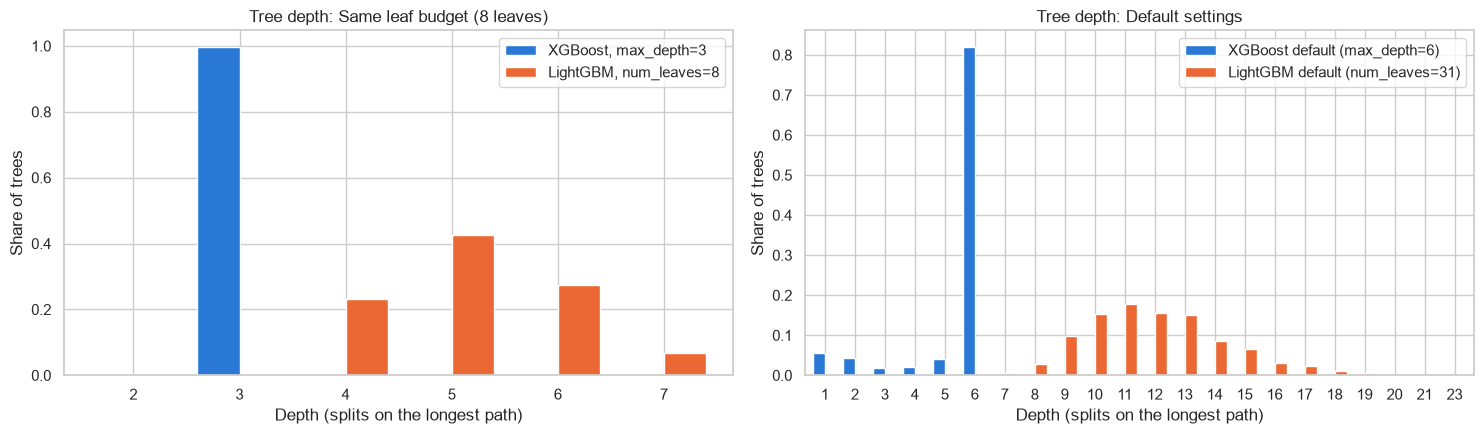

In [3]:
def xgb_tree_shapes(model, n_rounds):
    """Depth and number of leaves of the XGBoost trees of the first n_rounds rounds."""
    df = model.get_booster().trees_to_dataframe()
    df = df[df["Tree"] < n_rounds * num_classes]
    rows = []
    for tree, nodes in df.groupby("Tree"):
        children = {node.ID: (node.Yes, node.No) for node in nodes.itertuples() if node.Feature != "Leaf"}

        def depth(node_id):
            return 0 if node_id not in children else 1 + max(depth(child) for child in children[node_id])

        rows.append({"Depth": depth(f"{tree}-0"), "Leaves": int((nodes["Feature"] == "Leaf").sum())})
    return pd.DataFrame(rows)


def lgbm_tree_shapes(model, n_rounds):
    """Depth and number of leaves of the LightGBM trees of the first n_rounds rounds."""
    df = model.booster_.trees_to_dataframe()
    leaves = df[(df["tree_index"] < n_rounds * num_classes) & df["split_feature"].isna()]
    by_tree = leaves.groupby("tree_index")
    # node_depth counts the root as 1, so a leaf at node_depth d lies below d - 1 splits
    return pd.DataFrame({"Depth": by_tree["node_depth"].max() - 1, "Leaves": by_tree.size()}).reset_index(drop=True)


# Default models on the same training part (100 rounds each)
xgb_default = XGBClassifier(**XGB_DEFAULTS, tree_method="hist", random_state=42).fit(X_train_enc, y_train)
lgbm_default = LGBMClassifier(random_state=42, verbose=-1).fit(X_train_enc, y_train)

shapes = {
    "XGBoost, max_depth=3": xgb_tree_shapes(xgb_small, best_xgb + 1),
    "LightGBM, num_leaves=8": lgbm_tree_shapes(lgbm_small, best_lgbm + 1),
    "XGBoost default (max_depth=6)": xgb_tree_shapes(xgb_default, 100),
    "LightGBM default (num_leaves=31)": lgbm_tree_shapes(lgbm_default, 100),
}
display(pd.DataFrame({
    name: {
        "Trees": len(df), "Mean depth": df["Depth"].mean(), "Max depth": df["Depth"].max(),
        "Mean leaves": df["Leaves"].mean(), "Max leaves": df["Leaves"].max(),
    }
    for name, df in shapes.items()
}).T.round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, pair, title in [
    (axes[0], ["XGBoost, max_depth=3", "LightGBM, num_leaves=8"], "Same leaf budget (8 leaves)"),
    (axes[1], ["XGBoost default (max_depth=6)", "LightGBM default (num_leaves=31)"], "Default settings"),
]:
    depths = pd.DataFrame({name: shapes[name]["Depth"].value_counts(normalize=True) for name in pair}).fillna(0).sort_index()
    depths.plot.bar(ax=ax, color=["#2a78d6", "#eb6834"], width=0.8)
    ax.set_title(f"Tree depth: {title}", fontsize=12)
    ax.set_xlabel("Depth (splits on the longest path)")
    ax.set_ylabel("Share of trees")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

#### Interpretation of the tree shapes
* **Same leaf budget (8 leaves):** every XGBoost tree has depth 3 and on average 6.84 leaves. Some nodes are not split because no split has a positive gain or enough hessian weight. Every LightGBM tree uses all 8 leaves, at a mean depth of 5.17 and up to 7, the maximum possible with 8 leaves (a chain). With the same number of parameters per tree, the leaf-wise trees are deeper and more unbalanced.
* **Default settings:**
  * XGBoost's depth limit of 6 is reached by most trees (82% have depth 6), but they have only 18.82 leaves on average and at most 53 of the possible 64, because many branches stop early.
  * LightGBM's trees always use (almost) all of their 31 leaves (30.81 on average). Without a depth limit they become very deep: 11.96 splits on average and up to 23.
  * A default LightGBM tree therefore has more leaves and much longer paths than a default XGBoost tree. On 2,340 training houses, leaves at the end of such long paths describe small groups of houses.

### 2. The learning process
* **Learning curves** of the 8-leaf pair of Section 1: training and validation log-loss per round, with the best round.
* **Feature importance** of the two default models: total gain (sum of the loss reductions of all splits on a feature) and split count, for both libraries. The gain values of the two libraries are on different scales, so the comparison uses ranks.

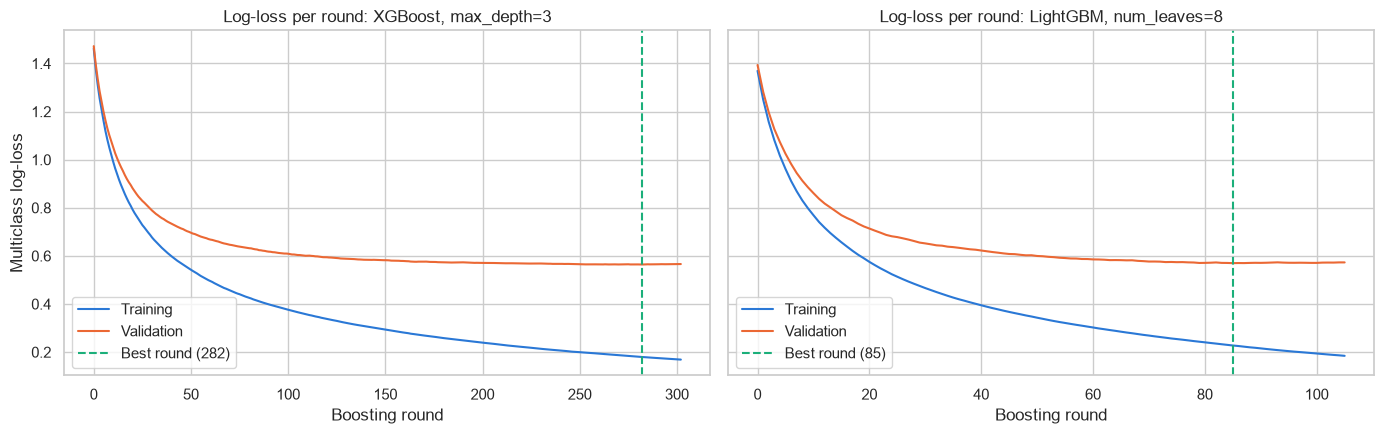

Log-loss at the best round


,Best round,Training,Validation,Gap
"XGBoost, max_depth=3",282.0,0.1797,0.5641,0.3844
"LightGBM, num_leaves=8",85.0,0.2274,0.5698,0.3424


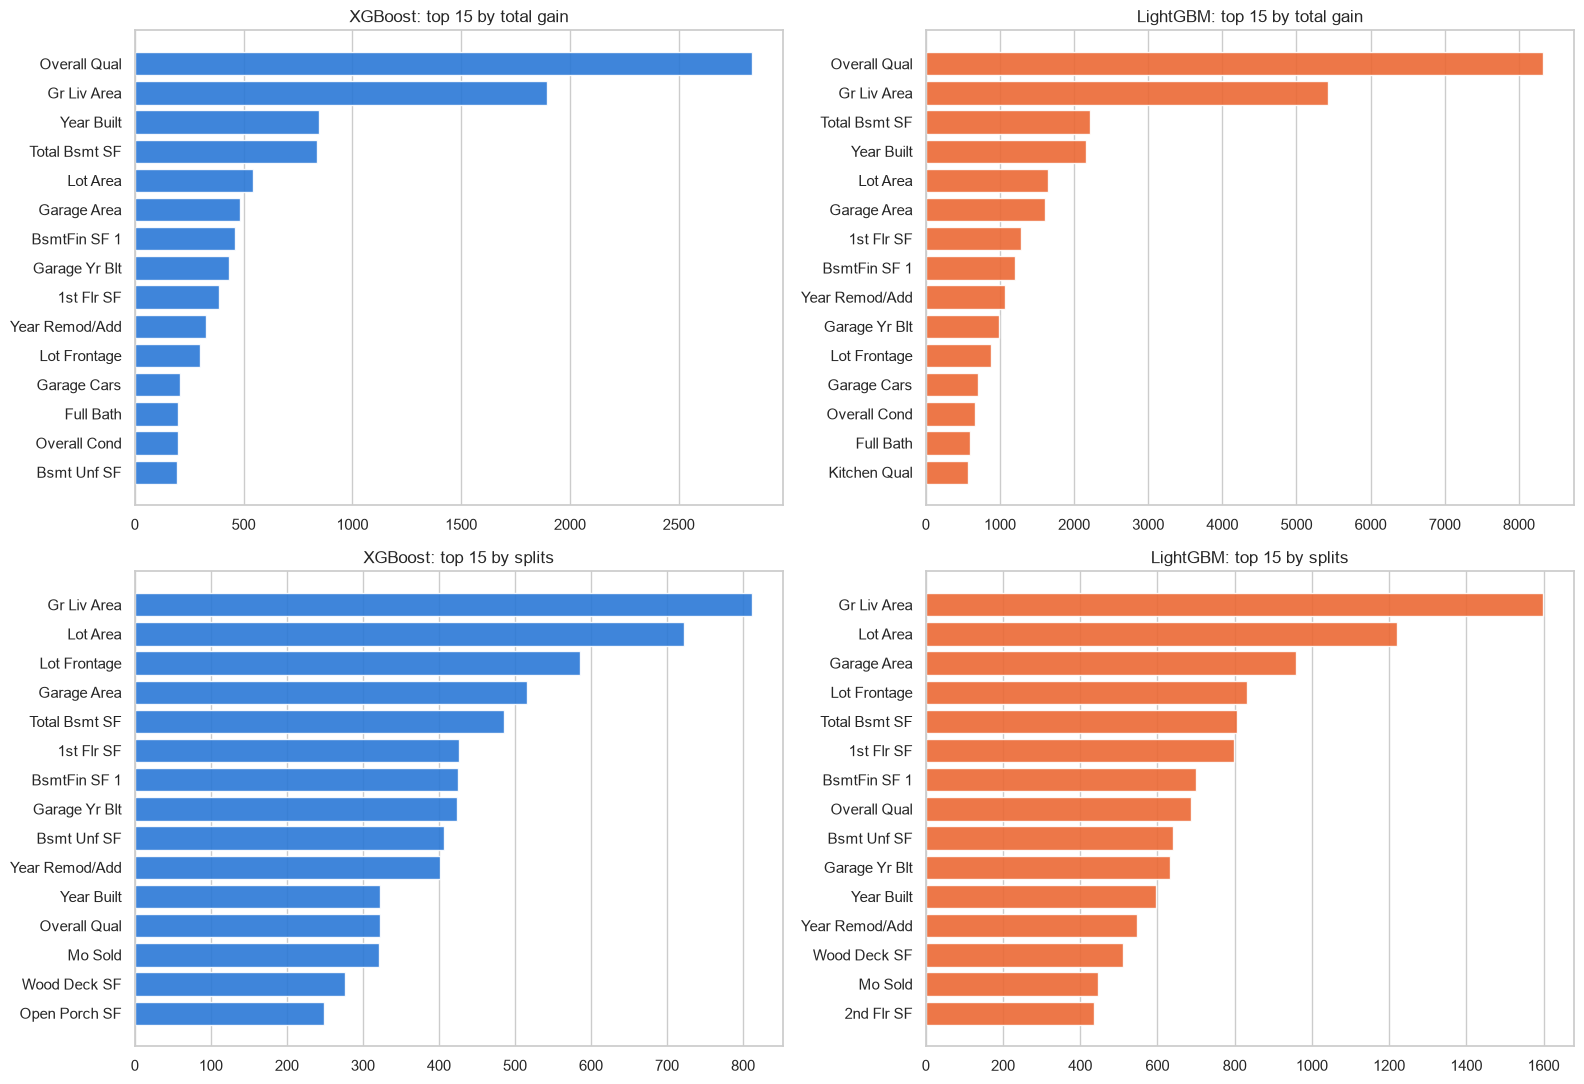

Rank correlation (Spearman) between the libraries, over all encoded features


,Spearman r
Total gain,0.949
Splits,0.946


Top 10 by total gain (LightGBM) with the ranks in both libraries


XGBoost          LightGBM       
               Total gain Splits Total gain Splits
Overall Qual            1     11          1      8
Gr Liv Area             2      1          2      1
Total Bsmt SF           4      5          3      5
Year Built              3     11          4     11
Lot Area                5      2          5      2
Garage Area             6      4          6      3
1st Flr SF              9      6          7      6
BsmtFin SF 1            7      7          8      7
Year Remod/Add         10     10          9     12
Garage Yr Blt           8      8         10     10

Features used in at least one split: XGBoost 155, LightGBM 159 of 200


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
curves = {
    "XGBoost, max_depth=3": (xgb_small.evals_result()["validation_0"]["mlogloss"],
                             xgb_small.evals_result()["validation_1"]["mlogloss"], best_xgb),
    "LightGBM, num_leaves=8": (lgbm_small.evals_result_["training"]["multi_logloss"],
                               lgbm_small.evals_result_["validation"]["multi_logloss"], best_lgbm),
}
for ax, (name, (train_curve, val_curve, best)) in zip(axes, curves.items()):
    ax.plot(train_curve, label="Training", color="#2a78d6")
    ax.plot(val_curve, label="Validation", color="#eb6834")
    ax.axvline(best, color="#1baf7a", linestyle="--", label=f"Best round ({best})")
    ax.set_title(f"Log-loss per round: {name}", fontsize=12)
    ax.set_xlabel("Boosting round")
    ax.legend()
axes[0].set_ylabel("Multiclass log-loss")
plt.tight_layout()
plt.show()

print("Log-loss at the best round")
display(pd.DataFrame({
    name: {"Best round": best, "Training": train_curve[best], "Validation": val_curve[best],
           "Gap": val_curve[best] - train_curve[best]}
    for name, (train_curve, val_curve, best) in curves.items()
}).T.round(4))

# Feature importance of the default models (LightGBM writes "_" instead of spaces in feature names)
lgbm_names = dict(zip(lgbm_default.booster_.feature_name(), X_train_enc.columns))
importance = pd.DataFrame({
    ("XGBoost", "Total gain"): pd.Series(xgb_default.get_booster().get_score(importance_type="total_gain")),
    ("XGBoost", "Splits"): pd.Series(xgb_default.get_booster().get_score(importance_type="weight")),
    ("LightGBM", "Total gain"): pd.Series(lgbm_default.booster_.feature_importance("gain"),
                                          index=lgbm_default.booster_.feature_name()).rename(index=lgbm_names),
    ("LightGBM", "Splits"): pd.Series(lgbm_default.booster_.feature_importance("split"),
                                      index=lgbm_default.booster_.feature_name()).rename(index=lgbm_names),
}).fillna(0)

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for row, measure in enumerate(["Total gain", "Splits"]):
    for col, (library, color) in enumerate([("XGBoost", "#2a78d6"), ("LightGBM", "#eb6834")]):
        top = importance[(library, measure)].sort_values().tail(15)
        axes[row, col].barh(top.index, top.values, color=color, alpha=0.9)
        axes[row, col].set_title(f"{library}: top 15 by {measure.lower()}", fontsize=12)
        axes[row, col].grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

ranks = importance.rank(ascending=False, method="min").astype(int)
print("Rank correlation (Spearman) between the libraries, over all encoded features")
display(pd.Series({
    measure: importance[("XGBoost", measure)].corr(importance[("LightGBM", measure)], method="spearman")
    for measure in ["Total gain", "Splits"]
}, name="Spearman r").round(3).to_frame())
print("Top 10 by total gain (LightGBM) with the ranks in both libraries")
display(ranks.sort_values(("LightGBM", "Total gain")).head(10))
print(f"Features used in at least one split: XGBoost {(importance[('XGBoost', 'Splits')] > 0).sum()}, "
      f"LightGBM {(importance[('LightGBM', 'Splits')] > 0).sum()} of {X_train_enc.shape[1]}")

#### Interpretation of the learning process
* **Learning curves:** both curves have the same shape. The training log-loss keeps falling, while the validation log-loss levels off and reaches its minimum at the best round. LightGBM gets there in 85 rounds instead of 282 because each leaf-wise tree reduces the loss more. Its best validation log-loss is slightly higher (0.5698 vs. 0.5641), and its gap at the best round is smaller (0.3424 vs. 0.3844), since it stops earlier with a less fitted training set (training log-loss 0.2274 vs. 0.1797).
* **Speed:** per round, LightGBM was about three times as fast here (0.2 s for 106 rounds vs. 1.7 s for 303 rounds), thanks to its histogram implementation and the feature bundling of the one-hot columns. Section 3 measures the time per fit on all 70 splits.
* **Feature importance:** the two libraries agree almost completely. The rank correlation over all 200 encoded features is 0.949 for total gain and 0.946 for split counts.
  * The 10 most important features by total gain are the same in both (`Overall Qual`, `Gr Liv Area`, `Total Bsmt SF`, `Year Built`, `Lot Area`, `Garage Area`, ...), only in a slightly different order.
  * By split count, `Gr Liv Area` leads in both. `Overall Qual` has the highest total gain in both but only split rank 11 (XGBoost) and 8 (LightGBM): a few very strong splits, as in notebook 03.
  * LightGBM uses 159 of the 200 encoded features, XGBoost 155.

  The different way of growing trees changes how the features are combined, not which features matter.

### 3. Default models on all 70 splits
LightGBM and XGBoost with their default hyperparameters, each with and without SMOTE, fitted and scored on the same 70 splits (holdout 10% / 20% and CV $k$ = 5 / 10, each with and without stratification). The paired differences compare the two libraries on the same splits.

In [5]:
DEFAULT_MODELS = {
    "XGBoost defaults": make_xgb(),
    "LightGBM defaults": make_lgbm(),
    "XGBoost defaults + SMOTE": make_xgb(smote=True),
    "LightGBM defaults + SMOTE": make_lgbm(smote=True),
}
default_results, default_seconds = run_models(DEFAULT_MODELS)

print("Test macro-F1, mean ± std over the splits of each setup")
display(summarize(default_results, "Test Macro-F1"))
print("Training vs. test macro-F1 over all 70 splits, and time per fit")
display(gap_table(default_results).join(default_seconds.round(2)))
print("Paired differences in macro-F1 on the same split")
display(paired(default_results, [
    ("LightGBM defaults", "XGBoost defaults"),
    ("LightGBM defaults + SMOTE", "XGBoost defaults + SMOTE"),
    ("LightGBM defaults + SMOTE", "LightGBM defaults"),
]))

Test macro-F1, mean ± std over the splits of each setup


Setup,Holdout 10%,"Holdout 10%, stratified",Holdout 20%,"Holdout 20%, stratified",CV k=5,"CV k=5, stratified",CV k=10,"CV k=10, stratified"
Variant,,,,,,,,
XGBoost defaults,0.7486 ± 0.0238,0.7596 ± 0.0342,0.7357 ± 0.0172,0.7546 ± 0.0245,0.7421 ± 0.0286,0.7494 ± 0.0236,0.7574 ± 0.0252,0.7546 ± 0.0432
LightGBM defaults,0.7497 ± 0.0332,0.7533 ± 0.0591,0.7347 ± 0.0174,0.7523 ± 0.0183,0.7375 ± 0.0222,0.7332 ± 0.0165,0.7483 ± 0.0276,0.7440 ± 0.0381
XGBoost defaults + SMOTE,0.7688 ± 0.0224,0.7800 ± 0.0239,0.7579 ± 0.0217,0.7671 ± 0.0189,0.7445 ± 0.0235,0.7479 ± 0.0204,0.7535 ± 0.0351,0.7634 ± 0.0342
LightGBM defaults + SMOTE,0.7705 ± 0.0303,0.7708 ± 0.0193,0.7578 ± 0.0217,0.7533 ± 0.0214,0.7549 ± 0.0259,0.7540 ± 0.0289,0.7506 ± 0.0242,0.7549 ± 0.0363


Training vs. test macro-F1 over all 70 splits, and time per fit


,Train Macro-F1,Test Macro-F1,Gap,Seconds per fit
Variant,,,,
XGBoost defaults,1.0,0.7509,0.2491,1.08
LightGBM defaults,1.0,0.7454,0.2546,0.79
XGBoost defaults + SMOTE,1.0,0.7624,0.2376,1.51
LightGBM defaults + SMOTE,1.0,0.7589,0.2411,1.06


Paired differences in macro-F1 on the same split


CV          \
                                                   Mean Difference     Std   
LightGBM defaults − XGBoost defaults                       -0.0100  0.0226   
LightGBM defaults + SMOTE − XGBoost defaults + ...         -0.0010  0.0225   
LightGBM defaults + SMOTE − LightGBM defaults               0.0108  0.0248   

                                                                 \
                                                   Better Worse   
LightGBM defaults − XGBoost defaults                 10.0  20.0   
LightGBM defaults + SMOTE − XGBoost defaults + ...   16.0  14.0   
LightGBM defaults + SMOTE − LightGBM defaults        21.0   9.0   

                                                           Holdout          \
                                                   Mean Difference     Std   
LightGBM defaults − XGBoost defaults                       -0.0021  0.0247   
LightGBM defaults + SMOTE − XGBoost defaults + ...         -0.0053  0.0199   
LightGBM defaults + SMOTE − LightGBM defaults               0.0156  0.0301   

                                                                 \
                                                   Better Worse   
LightGBM defaults − XGBoost defaults                 19.0  21.0   
LightGBM defaults + SMOTE − XGBoost defaults + ...   15.0  25.0   
LightGBM defaults + SMOTE − LightGBM defaults        25.0  15.0   

                                                     All 70 splits          \
                                                   Mean Difference     Std   
LightGBM defaults − XGBoost defaults                       -0.0055  0.0239   
LightGBM defaults + SMOTE − XGBoost defaults + ...         -0.0035  0.0210   
LightGBM defaults + SMOTE − LightGBM defaults               0.0136  0.0278   

                                                                 
                                                   Better Worse  
LightGBM defaults − XGBoost defaults                 29.0  41.0  
LightGBM defaults + SMOTE − XGBoost defaults + ...   31.0  39.0  
LightGBM defaults + SMOTE − LightGBM defaults        46.0  24.0

#### Interpretation of the default models
* **Without SMOTE, LightGBM's defaults are slightly worse:** a mean test macro-F1 of 0.7454 vs. 0.7509. It is worse by 0.0055 on average and better on only 29 of 70 splits; the difference comes mostly from the cross-validation folds (−0.0100, better on 10 of 30). It has the largest gap of the four models (0.2546). LightGBM's defaults (31 leaves, no depth limit, at least 20 houses per leaf) are meant for much larger data sets. On 2,340 training houses, the deep leaf-wise trees of Section 1.1 isolate small groups and overfit.
* **With SMOTE, the two are close:** 0.7589 vs. 0.7624 (−0.0035, better on 31 of 70).
* **SMOTE helps LightGBM more consistently than XGBoost:** +0.0136 macro-F1 over all 70 splits, better on 46 of 70. The gain appears on both the holdout splits (+0.0156) and the cross-validation folds (+0.0108). For XGBoost with default hyperparameters, the gain was on the holdout splits only (notebook 04).
* **Speed:** LightGBM needs 0.79 s per fit vs. 1.08 s for XGBoost (1.06 vs. 1.51 s with SMOTE), including the one-hot encoding and the predictions.

### 4. Manual tuning of the leaf-wise growth
A short manual experiment on the two hyperparameters that control the leaf-wise growth, one at a time, with all others at their default, on the same 5 stratified folds as in notebook 05:
* `num_leaves` (default 31): the size of every tree.
* `min_child_samples` (default 20): the minimum number of (training) houses in a leaf, which stops the leaf-wise growth from isolating small groups.

Both are run without and with SMOTE.

num_leaves: 5-fold stratified CV


No SMOTE                                          \
           Train Macro-F1 Test Macro-F1 Test Macro-F1 Std     Gap   
num_leaves                                                          
4                  0.9044        0.7331            0.0171  0.1714   
8                  0.9813        0.7426            0.0160  0.2388   
16                 0.9997        0.7371            0.0231  0.2626   
31                 1.0000        0.7332            0.0165  0.2668   
63                 1.0000        0.7371            0.0198  0.2629   
127                1.0000        0.7389            0.0254  0.2611   

                    SMOTE                                          
           Train Macro-F1 Test Macro-F1 Test Macro-F1 Std     Gap  
num_leaves                                                         
4                  0.8727        0.7401            0.0208  0.1326  
8                  0.9635        0.7395            0.0312  0.2240  
16                 0.9986        0.7470            0.0283  0.2516  
31                 1.0000        0.7540            0.0289  0.2460  
63                 1.0000        0.7526            0.0267  0.2474  
127                1.0000        0.7556            0.0192  0.2444

min_child_samples: 5-fold stratified CV


No SMOTE                                          \
                  Train Macro-F1 Test Macro-F1 Test Macro-F1 Std     Gap   
min_child_samples                                                          
5                         1.0000        0.7370            0.0387  0.2630   
10                        1.0000        0.7342            0.0273  0.2658   
20                        1.0000        0.7332            0.0165  0.2668   
40                        1.0000        0.7493            0.0212  0.2507   
80                        0.9996        0.7494            0.0190  0.2501   

                           SMOTE                                          
                  Train Macro-F1 Test Macro-F1 Test Macro-F1 Std     Gap  
min_child_samples                                                         
5                            1.0        0.7563            0.0261  0.2437  
10                           1.0        0.7490            0.0217  0.2510  
20                           1.0        0.7540            0.0289  0.2460  
40                           1.0        0.7496            0.0276  0.2504  
80                           1.0        0.7579            0.0216  0.2421

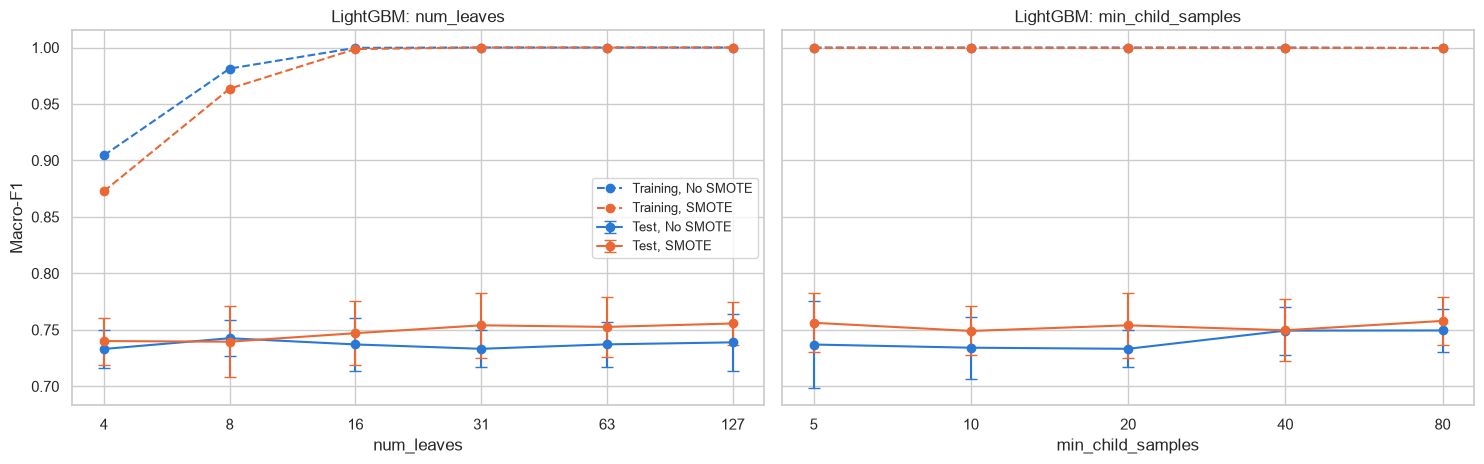

In [6]:
SWEEP_VALUES = {"num_leaves": [4, 8, 16, 31, 63, 127], "min_child_samples": [5, 10, 20, 40, 80]}
sweeps = {}
for param, values in SWEEP_VALUES.items():
    for smote in (False, True):
        label = "SMOTE" if smote else "No SMOTE"
        sweeps[(param, label)] = pd.DataFrame(
            [{param: value, **cv_scores(make_lgbm(smote=smote, **{param: value}))} for value in values]
        ).set_index(param)

for param in SWEEP_VALUES:
    print(f"{param}: 5-fold stratified CV")
    display(pd.concat(
        {label: sweeps[(param, label)][["Train Macro-F1", "Test Macro-F1", "Test Macro-F1 Std", "Gap"]]
         for label in ["No SMOTE", "SMOTE"]}, axis=1
    ).round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
for ax, param in zip(axes, SWEEP_VALUES):
    for label, color in [("No SMOTE", "#2a78d6"), ("SMOTE", "#eb6834")]:
        df = sweeps[(param, label)]
        positions = range(len(df))
        ax.plot(positions, df["Train Macro-F1"], marker="o", linestyle="--", color=color, label=f"Training, {label}")
        ax.errorbar(positions, df["Test Macro-F1"], yerr=df["Test Macro-F1 Std"], marker="o", capsize=4,
                    color=color, label=f"Test, {label}")
    ax.set_xticks(list(positions), df.index.astype(str))
    ax.set_xlabel(param)
    ax.set_title(f"LightGBM: {param}", fontsize=12)
axes[0].set_ylabel("Macro-F1")
axes[0].legend(fontsize=9)
plt.tight_layout()
plt.show()

#### Interpretation of the manual tuning
* **`num_leaves` without SMOTE:** the best value is 8 (0.7426 vs. 0.7332 for the default 31), with a training macro-F1 of 0.9813. With 4 leaves, the model is too simple (0.7331, training 0.9044). From 16 leaves on, every tree is large enough to memorize the training houses (training 1.0), and the test score stays at 0.733–0.739. As for XGBoost (notebook 05), smaller trees reduce the gap (0.1714 at 4 leaves), but the test score does not follow beyond 8 leaves.
* **`num_leaves` with SMOTE:** the opposite trend. Small trees are worse (0.7401 at 4, 0.7395 at 8), and large trees are best (0.7540 at 31, 0.7556 at 127). This matches XGBoost with SMOTE (notebook 05.1), where depth 2 hurt: with six equally large classes in the training data, the trees have to separate all of them, and the doubled training data supports more leaves.
* **`min_child_samples` without SMOTE:** larger leaves clearly help: 0.7493 at 40 and 0.7494 at 80 houses per leaf, +0.016 over the default of 20 (0.7332). This is the most effective single change for LightGBM without SMOTE. It stops the leaf-wise growth from carving out small groups of training houses at the end of long paths, the main source of overfitting seen in Section 1.1. The training macro-F1 still stays at 1.0 (0.9996 at 80): with 100 rounds, the model still memorizes the training houses, just with fewer tiny leaves.
* **`min_child_samples` with SMOTE:** no clear trend (0.7490–0.7579), within the noise. With about 829 houses per class in the training part, small classes no longer end up in tiny leaves.

### 5. Bayesian optimization with Optuna (`TPESampler`)
The same procedure as for XGBoost in notebooks 05 and 05.1: mean macro-F1 over the same 5 stratified folds, `TPESampler` with 10 random startup trials and seed 42, `MedianPruner`, and 100 trials, once without and once with SMOTE. Both studies are stored in the SQLite database `optuna_ames_housing.db` (`lightgbm_macro_f1_tpe` and `lightgbm_smote_macro_f1_tpe`), so an interrupted run resumes where it stopped.

The search space covers the LightGBM counterparts of the nine XGBoost hyperparameters of notebook 05: `num_leaves` instead of `max_depth`, `min_child_samples` (houses per leaf) instead of `min_child_weight` (hessian per leaf), `min_split_gain` instead of `gamma`; the learning rate, number of rounds, row and column sampling and the L1/L2 penalties have the same ranges. Row sampling needs `subsample_freq=1` in LightGBM (resample every round).

In [7]:
N_TRIALS = 100


def lgbm_params(trial):
    """One LightGBM configuration from the search space."""
    return {
        "num_leaves": trial.suggest_int("num_leaves", 4, 128, log=True),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "n_estimators": trial.suggest_int("n_estimators", 100, 1000, step=50),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 100, log=True),
        "subsample": trial.suggest_float("subsample", 0.4, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.2, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.01, 100.0, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 0.001, 10.0, log=True),
        "min_split_gain": trial.suggest_float("min_split_gain", 0.0, 5.0),
    }


def make_objective(smote):
    def objective(trial):
        """Mean macro-F1 over the 5 stratified folds for one hyperparameter combination."""
        model = make_lgbm(smote=smote, subsample_freq=1, **lgbm_params(trial))
        fold_scores = []
        for step, split in enumerate(cv5):
            fitted = clone(model).fit(X.loc[split["train"]], y.loc[split["train"]])
            fold_scores.append(f1_score(y.loc[split["test"]], fitted.predict(X.loc[split["test"]]), average="macro"))
            # Running mean after each fold, so the pruner can stop clearly bad trials early
            trial.report(np.mean(fold_scores), step)
            if trial.should_prune():
                raise optuna.TrialPruned()
        return np.mean(fold_scores)
    return objective


def print_progress(study, trial):
    """Short status line after every 25 trials."""
    if (trial.number + 1) % 25 == 0:
        print(f"  {trial.number + 1:>3} trials: best macro-F1 {study.best_value:.4f} (trial {study.best_trial.number})")


studies = {}
for smote, study_name in [(False, "lightgbm_macro_f1_tpe"), (True, "lightgbm_smote_macro_f1_tpe")]:
    study = optuna.create_study(
        study_name=study_name, storage=STORAGE, load_if_exists=True, direction="maximize",
        sampler=TPESampler(n_startup_trials=10, seed=42), pruner=MedianPruner(n_startup_trials=10, n_warmup_steps=1),
    )
    # Resume: only the trials that are not yet stored in the database are run
    remaining = N_TRIALS - len(study.trials)
    print(f"{study_name}: {len(study.trials)} trials stored, running {max(remaining, 0)} more")
    if remaining > 0:
        study.optimize(make_objective(smote), n_trials=remaining, callbacks=[print_progress])
    studies["SMOTE" if smote else "No SMOTE"] = study

for label, study in studies.items():
    trials = study.trials_dataframe()
    print(f"\n{label}: trial states {trials['state'].value_counts().to_dict()}, "
          f"best trial #{study.best_trial.number} with mean macro-F1 {study.best_value:.4f}")
    top = trials[trials["state"] == "COMPLETE"].sort_values("value", ascending=False).head(5)
    top = top[["number", "value"] + [col for col in trials if col.startswith("params_")]]
    display(top.rename(columns=lambda col: col.removeprefix("params_")).set_index("number").round(4))

lightgbm_macro_f1_tpe: 0 trials stored, running 100 more


   25 trials: best macro-F1 0.7484 (trial 22)


   50 trials: best macro-F1 0.7541 (trial 38)


   75 trials: best macro-F1 0.7562 (trial 65)


  100 trials: best macro-F1 0.7568 (trial 84)
lightgbm_smote_macro_f1_tpe: 0 trials stored, running 100 more


...

   75 trials: best macro-F1 0.7690 (trial 65)


  100 trials: best macro-F1 0.7690 (trial 65)

No SMOTE: trial states {'COMPLETE': 76, 'PRUNED': 24}, best trial #84 with mean macro-F1 0.7568


,value,colsample_bytree,learning_rate,min_child_samples,min_split_gain,n_estimators,num_leaves,reg_alpha,reg_lambda,subsample
number,,,,,,,,,,
84,0.7568,0.4741,0.0282,14,0.3388,500,22,0.2030,0.0267,0.5445
65,0.7562,0.5325,0.0237,12,0.1418,550,12,0.1712,0.0128,0.5593
38,0.7541,0.4690,0.0250,15,0.2340,650,25,0.3428,0.2741,0.5304
44,0.7522,0.4697,0.0480,14,0.3896,700,23,0.3139,0.0864,0.5482
52,0.7518,0.4379,0.0554,7,0.1077,550,13,0.3817,0.0137,0.5140



SMOTE: trial states {'COMPLETE': 100}, best trial #65 with mean macro-F1 0.7690


,value,colsample_bytree,learning_rate,min_child_samples,min_split_gain,n_estimators,num_leaves,reg_alpha,reg_lambda,subsample
number,,,,,,,,,,
65,0.7690,0.5109,0.0148,21,0.0753,750,16,0.2645,0.0883,0.7903
98,0.7684,0.5864,0.0195,17,0.4749,750,23,0.5917,0.2529,0.7499
92,0.7662,0.4491,0.0257,18,0.0350,850,23,2.2644,0.8161,0.7551
58,0.7660,0.5429,0.0193,18,0.0383,750,21,1.4608,0.3045,0.7827
88,0.7655,0.4632,0.0283,21,0.0664,750,29,1.3197,0.3609,0.7654


#### Interpretation of the search results
* **Without SMOTE:** 76 trials finished and 24 were pruned. The best trial, #84, reaches 0.7568 on the 5 folds, almost the same as the best XGBoost trial of notebook 05 (0.7556). Its hyperparameters: `num_leaves` 22, `learning_rate` 0.0282 with 500 rounds, `min_child_samples` 14, `subsample` 0.545, `colsample_bytree` 0.474, `reg_lambda` 0.027, `reg_alpha` 0.203 and `min_split_gain` 0.339. The 5 best trials agree:
  * 12–25 leaves
  * learning rate 0.024–0.055 with 500–700 rounds
  * 7–15 houses per leaf
  * `subsample` 0.51–0.56 and `colsample_bytree` 0.44–0.53
  * a small L2 penalty (0.013–0.27), a moderate L1 penalty (0.17–0.38) and `min_split_gain` 0.11–0.39

  Like XGBoost in notebook 05, the best LightGBM combines a small learning rate, many rounds and strong row and column sampling. Unlike the manual experiment, it uses small leaves (7–15 houses): the sampling and the penalties already prevent the overfitting that larger leaves fought alone.
* **With SMOTE:** all 100 trials finished. The best trial, #65, reaches 0.7690, higher than the best XGBoost trial with SMOTE on the same folds (0.7654, notebook 05.1). Its hyperparameters: `num_leaves` 16, `learning_rate` 0.0148 with 750 rounds, `min_child_samples` 21, `subsample` 0.790, `colsample_bytree` 0.511, `reg_lambda` 0.088, `reg_alpha` 0.265 and `min_split_gain` 0.075. The 5 best trials agree:
  * 16–29 leaves
  * a smaller learning rate (0.015–0.028) with more rounds (750–850)
  * 17–21 houses per leaf
  * less row sampling (`subsample` 0.75–0.79)
* **Progress:** without SMOTE, the best value still improved late in the search (0.7484 after 25 trials, 0.7541 after 50, 0.7562 after 75, 0.7568 at trial 84). With SMOTE, it improved until trial 65 (0.7690) and then stayed. LightGBM kept finding slightly better trials for longer than XGBoost (notebook 05 converged at trial 53), but after trial 50 the gain was only +0.0027.

#### 5.1 Visualizations of the optimization process
For both studies: the optimization history, the hyperparameter importance (fANOVA, fixed seed) and the slice plots.

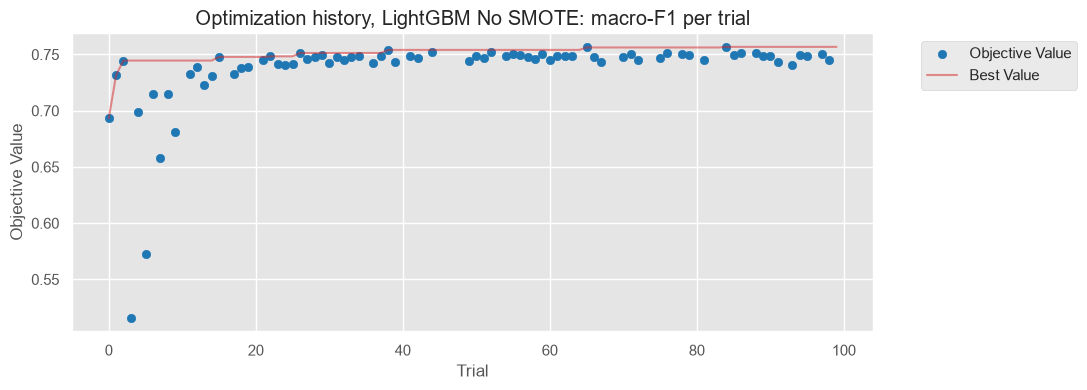

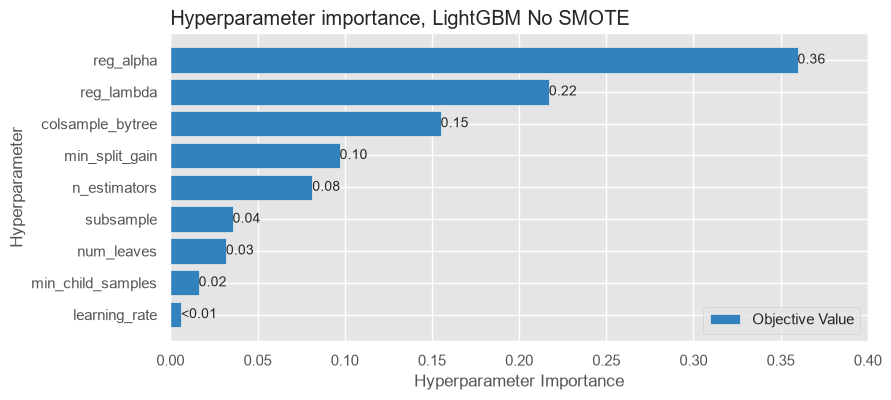

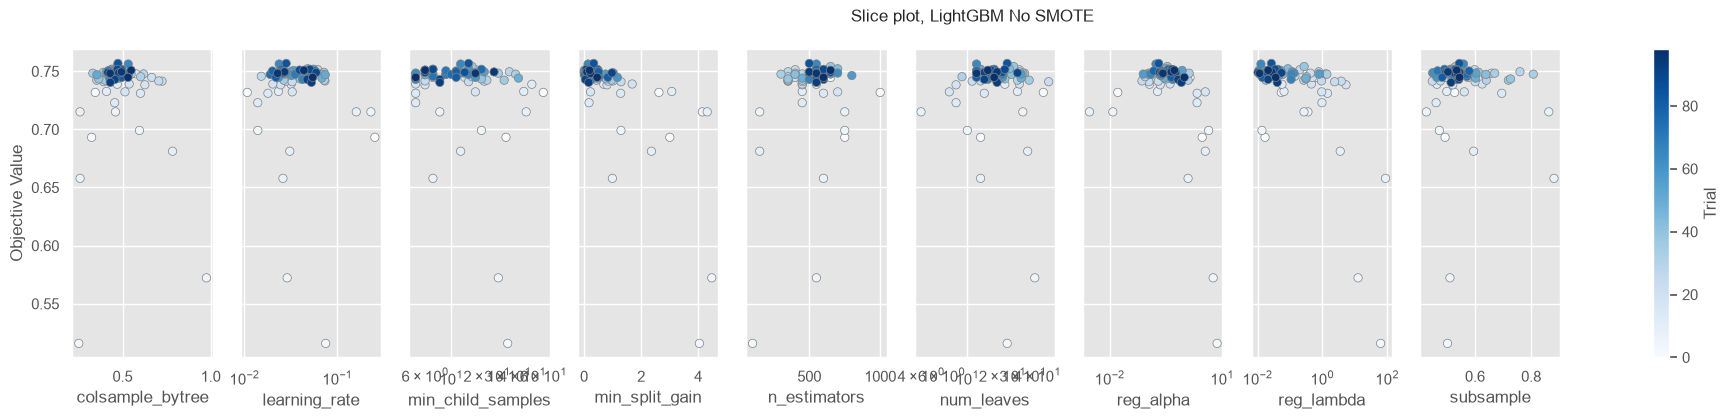

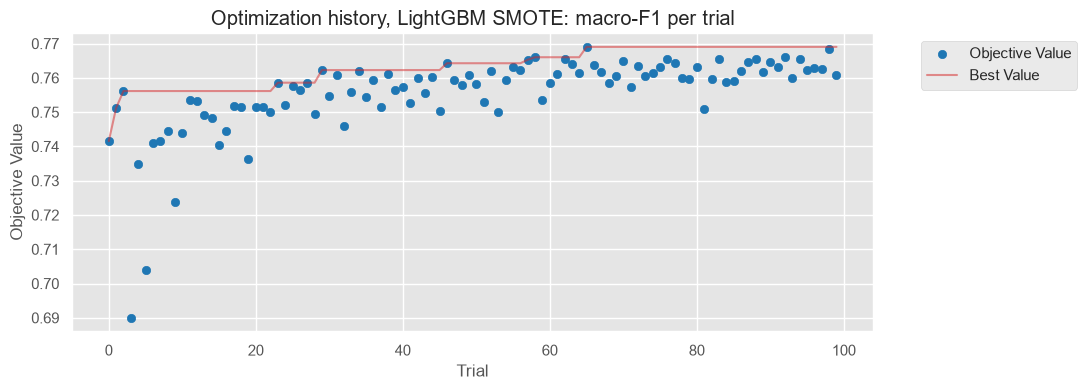

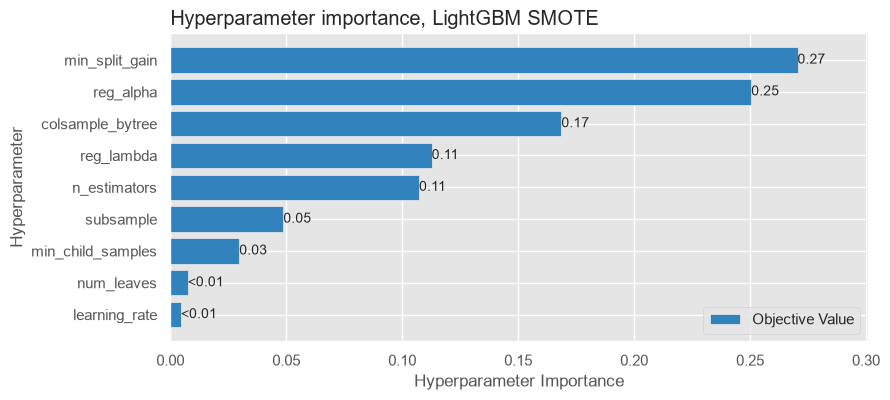

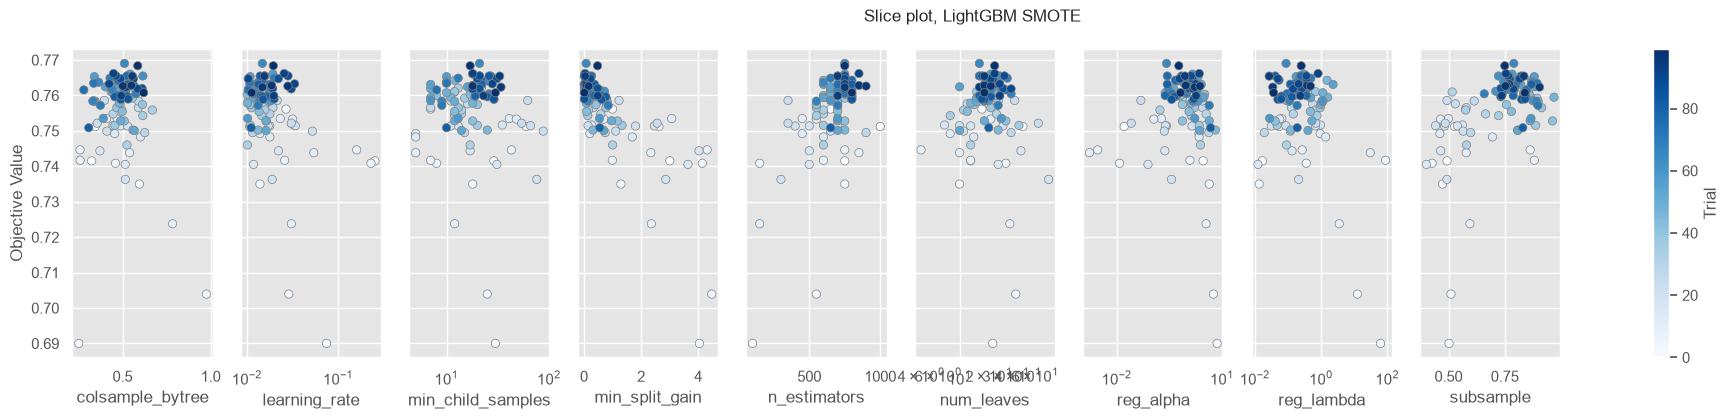

In [8]:
evaluator = optuna.importance.FanovaImportanceEvaluator(seed=42)
for label, study in studies.items():
    ax = optuna_plots.plot_optimization_history(study)
    ax.figure.set_size_inches(11, 4)
    ax.set_title(f"Optimization history, LightGBM {label}: macro-F1 per trial")
    plt.show()

    ax = optuna_plots.plot_param_importances(study, evaluator=evaluator)
    ax.figure.set_size_inches(9, 4)
    ax.set_title(f"Hyperparameter importance, LightGBM {label}", loc="left")
    plt.show()

    axes = optuna_plots.plot_slice(study)
    axes.flat[0].figure.set_size_inches(24, 4)
    axes.flat[0].figure.suptitle(f"Slice plot, LightGBM {label}")
    plt.show()

#### Interpretation of the optimization plots
* **History:** in both studies, the 10 random startup trials spread widely (down to about 0.52 without SMOTE), and from trial 10 on TPE samples almost only in a narrow band just below the best value, as for XGBoost.
* **Importance:** without SMOTE, `reg_alpha` (0.36) and `reg_lambda` (0.22) explain most of the variation, followed by `colsample_bytree` (0.15) and `min_split_gain` (0.10). With SMOTE, `min_split_gain` (0.27), `reg_alpha` (0.25) and `colsample_bytree` (0.17) lead. As in notebooks 05 and 05.1, this comes from the bad trials with large penalties or a large minimum split gain (right end of the slice plots). In the good region, these hyperparameters hardly matter.
* **`num_leaves` and `learning_rate`** have an importance of at most 0.03 in both studies, although they define the model's capacity. TPE quickly settled on moderate trees (12–29 leaves) and small learning rates, and within this region they hardly change the score.

### 6. Final comparison on all 70 splits
The tuned LightGBM models (best Optuna trial, without and with SMOTE) against the tuned XGBoost reference models, all fitted and scored on the same 70 splits. The tuning used only "CV k=5, stratified", so the other 65 splits are a fairer test (notebook 05, Section 4).

In [9]:
FINAL_MODELS = {
    "XGBoost tuned (nb 05)": make_xgb(**XGB_TUNED),
    "LightGBM tuned": make_lgbm(subsample_freq=1, **studies["No SMOTE"].best_params),
    "XGBoost SMOTE + manual (nb 05.1)": make_xgb(smote=True, **XGB_SMOTE_MANUAL),
    "LightGBM tuned + SMOTE": make_lgbm(smote=True, subsample_freq=1, **studies["SMOTE"].best_params),
}
final_results, final_seconds = run_models(FINAL_MODELS)

print("Test macro-F1, mean ± std over the splits of each setup")
display(summarize(final_results, "Test Macro-F1"))
print("Test accuracy, mean ± std over the splits of each setup")
display(summarize(final_results, "Test Accuracy"))
print("Training vs. test macro-F1 over all 70 splits, and time per fit")
display(gap_table(final_results).join(final_seconds.round(2)))
print("Paired differences in macro-F1 on the same split")
display(paired(final_results, [
    ("LightGBM tuned", "XGBoost tuned (nb 05)"),
    ("LightGBM tuned + SMOTE", "XGBoost SMOTE + manual (nb 05.1)"),
    ("LightGBM tuned + SMOTE", "LightGBM tuned"),
]))

Test macro-F1, mean ± std over the splits of each setup


Setup,Holdout 10%,"Holdout 10%, stratified",Holdout 20%,"Holdout 20%, stratified",CV k=5,"CV k=5, stratified",CV k=10,"CV k=10, stratified"
Variant,,,,,,,,
XGBoost tuned (nb 05),0.7595 ± 0.0290,0.7699 ± 0.0381,0.7563 ± 0.0145,0.7656 ± 0.0198,0.7549 ± 0.0190,0.7556 ± 0.0187,0.7516 ± 0.0212,0.7502 ± 0.0481
LightGBM tuned,0.7649 ± 0.0281,0.7652 ± 0.0516,0.7562 ± 0.0184,0.7628 ± 0.0165,0.7538 ± 0.0218,0.7568 ± 0.0284,0.7549 ± 0.0193,0.7515 ± 0.0451
XGBoost SMOTE + manual (nb 05.1),0.7796 ± 0.0240,0.7830 ± 0.0223,0.7672 ± 0.0169,0.7779 ± 0.0185,0.7632 ± 0.0234,0.7606 ± 0.0267,0.7671 ± 0.0269,0.7703 ± 0.0387
LightGBM tuned + SMOTE,0.7786 ± 0.0265,0.7872 ± 0.0192,0.7666 ± 0.0171,0.7719 ± 0.0238,0.7557 ± 0.0307,0.7690 ± 0.0212,0.7679 ± 0.0317,0.7677 ± 0.0379


Test accuracy, mean ± std over the splits of each setup


Setup,Holdout 10%,"Holdout 10%, stratified",Holdout 20%,"Holdout 20%, stratified",CV k=5,"CV k=5, stratified",CV k=10,"CV k=10, stratified"
Variant,,,,,,,,
XGBoost tuned (nb 05),0.7683 ± 0.0226,0.7799 ± 0.0260,0.7704 ± 0.0118,0.7759 ± 0.0077,0.7648 ± 0.0150,0.7768 ± 0.0202,0.7685 ± 0.0199,0.7716 ± 0.0312
LightGBM tuned,0.7720 ± 0.0212,0.7744 ± 0.0227,0.7660 ± 0.0131,0.7750 ± 0.0112,0.7665 ± 0.0190,0.7750 ± 0.0224,0.7689 ± 0.0163,0.7713 ± 0.0275
XGBoost SMOTE + manual (nb 05.1),0.7700 ± 0.0218,0.7788 ± 0.0209,0.7651 ± 0.0102,0.7742 ± 0.0129,0.7634 ± 0.0166,0.7634 ± 0.0238,0.7689 ± 0.0226,0.7716 ± 0.0310
LightGBM tuned + SMOTE,0.7713 ± 0.0199,0.7826 ± 0.0192,0.7651 ± 0.0110,0.7730 ± 0.0164,0.7562 ± 0.0226,0.7740 ± 0.0259,0.7720 ± 0.0164,0.7733 ± 0.0331


Training vs. test macro-F1 over all 70 splits, and time per fit


,Train Macro-F1,Test Macro-F1,Gap,Seconds per fit
Variant,,,,
XGBoost tuned (nb 05),0.9883,0.7583,0.2300,3.56
LightGBM tuned,0.9987,0.7587,0.2401,1.56
XGBoost SMOTE + manual (nb 05.1),0.9968,0.7724,0.2244,5.90
LightGBM tuned + SMOTE,0.9973,0.7717,0.2255,3.90


Paired differences in macro-F1 on the same split


CV          \
                                                   Mean Difference     Std   
LightGBM tuned − XGBoost tuned (nb 05)                      0.0015  0.0110   
LightGBM tuned + SMOTE − XGBoost SMOTE + manual...         -0.0005  0.0194   
LightGBM tuned + SMOTE − LightGBM tuned                     0.0121  0.0261   

                                                                 \
                                                   Better Worse   
LightGBM tuned − XGBoost tuned (nb 05)               16.0  14.0   
LightGBM tuned + SMOTE − XGBoost SMOTE + manual...   14.0  16.0   
LightGBM tuned + SMOTE − LightGBM tuned              19.0  11.0   

                                                           Holdout          \
                                                   Mean Difference     Std   
LightGBM tuned − XGBoost tuned (nb 05)                     -0.0005  0.0171   
LightGBM tuned + SMOTE − XGBoost SMOTE + manual...         -0.0008  0.0107   
LightGBM tuned + SMOTE − LightGBM tuned                     0.0138  0.0304   

                                                                 \
                                                   Better Worse   
LightGBM tuned − XGBoost tuned (nb 05)               23.0  17.0   
LightGBM tuned + SMOTE − XGBoost SMOTE + manual...   18.0  22.0   
LightGBM tuned + SMOTE − LightGBM tuned              28.0  12.0   

                                                     All 70 splits          \
                                                   Mean Difference     Std   
LightGBM tuned − XGBoost tuned (nb 05)                      0.0004  0.0147   
LightGBM tuned + SMOTE − XGBoost SMOTE + manual...         -0.0007  0.0149   
LightGBM tuned + SMOTE − LightGBM tuned                     0.0131  0.0285   

                                                                 
                                                   Better Worse  
LightGBM tuned − XGBoost tuned (nb 05)               39.0  31.0  
LightGBM tuned + SMOTE − XGBoost SMOTE + manual...   32.0  38.0  
LightGBM tuned + SMOTE − LightGBM tuned              47.0  23.0

#### Interpretation of the final comparison
* **The tuned models of the two libraries are practically equal:**
  * without SMOTE: 0.7587 (LightGBM) vs. 0.7583 (XGBoost) mean test macro-F1 over all 70 splits, a difference of +0.0004, with LightGBM better on 39 of 70 splits
  * with SMOTE: 0.7717 vs. 0.7724, a difference of −0.0007, with LightGBM better on 32 of 70

  Neither difference is consistent in the holdout or the cross-validation splits. With SMOTE, XGBoost has the higher mean in 5 of the 8 setups and LightGBM in 3, one of them its own tuning folds ("CV k=5, stratified": 0.7690 vs. 0.7606).
* **The paired differences between the libraries have a small spread** (standard deviation 0.0147–0.0149, vs. about 0.02–0.03 in the earlier comparisons): on most splits, both libraries make very similar predictions. The leaf-wise and depth-wise trees end up describing the same function.
* **SMOTE helps LightGBM as much as XGBoost:** +0.0131 for the tuned LightGBM (better on 47 of 70), on both the holdout splits (+0.0138) and the cross-validation folds (+0.0121). For XGBoost, notebook 05.1 found +0.0141.
* **Bias-variance:** the tuned LightGBM models fit the training houses almost perfectly (training macro-F1 0.9987 without and 0.9973 with SMOTE). The tuned XGBoost without SMOTE is more regularized (0.9883), but both reach the same test score. Without SMOTE, the gap is 0.2401 for LightGBM and 0.2300 for XGBoost.
* **Speed:** LightGBM needs 1.56 s per fit vs. 3.56 s for XGBoost without SMOTE (2.3 times faster), and 3.90 vs. 5.90 s with SMOTE (1.5 times faster). On this small data set the difference is a few seconds per fit, but it adds up over the hundreds of fits of a hyperparameter search.

#### 6.1 Diagnostics per class
Pooled out-of-fold predictions of the 5 stratified folds for the four tuned models: F1 and recall per class, and the confusion matrices of the two SMOTE models.

Pooled out-of-fold metrics


,Accuracy,Macro Precision,Macro Recall,Macro F1
Model,,,,
XGBoost tuned (nb 05),0.7768,0.7885,0.7368,0.7592
LightGBM tuned,0.7750,0.7910,0.7376,0.7608
XGBoost SMOTE + manual (nb 05.1),0.7634,0.7667,0.7589,0.7626
LightGBM tuned + SMOTE,0.7740,0.7744,0.7665,0.7704


F1 per class


,XGBoost tuned (nb 05),LightGBM tuned,XGBoost SMOTE + manual (nb 05.1),LightGBM tuned + SMOTE
< 100k,0.7198,0.7330,0.7102,0.7281
100k–130k,0.6754,0.6815,0.6577,0.6751
130k–180k,0.8111,0.8131,0.7902,0.8023
180k–250k,0.7900,0.7813,0.7828,0.7886
250k–400k,0.8249,0.8036,0.8219,0.8249
≥ 400k,0.7339,0.7523,0.8130,0.8033


Recall per class


,XGBoost tuned (nb 05),LightGBM tuned,XGBoost SMOTE + manual (nb 05.1),LightGBM tuned + SMOTE
< 100k,0.6667,0.6835,0.6878,0.7173
100k–130k,0.6582,0.6601,0.6699,0.6778
130k–180k,0.8456,0.8485,0.7905,0.8069
180k–250k,0.7865,0.7836,0.7851,0.7880
250k–400k,0.8186,0.7884,0.8136,0.8186
≥ 400k,0.6452,0.6613,0.8065,0.7903


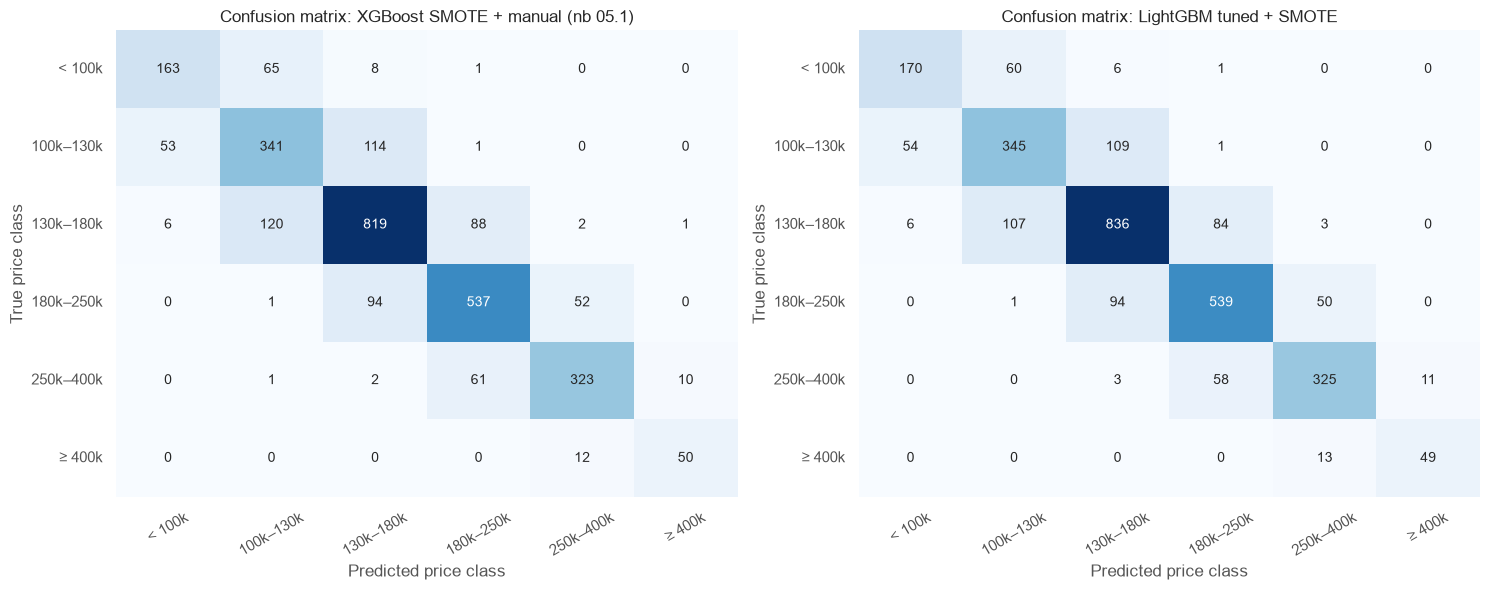

In [10]:
def out_of_fold_predictions(model):
    """Predicted class of every house from the fold in which it is a test house."""
    pred = np.zeros(len(y), dtype=int)
    for split in cv5:
        fitted = clone(model).fit(X.loc[split["train"]], y.loc[split["train"]])
        pred[y.index.get_indexer(split["test"])] = np.ravel(fitted.predict(X.loc[split["test"]]))
    return pred


y_arr = y.to_numpy()
oof_pred = {name: out_of_fold_predictions(model) for name, model in FINAL_MODELS.items()}

print("Pooled out-of-fold metrics")
display(pd.DataFrame([
    {
        "Model": name,
        "Accuracy": accuracy_score(y_arr, pred),
        "Macro Precision": precision_score(y_arr, pred, average="macro"),
        "Macro Recall": recall_score(y_arr, pred, average="macro"),
        "Macro F1": f1_score(y_arr, pred, average="macro"),
    }
    for name, pred in oof_pred.items()
]).set_index("Model").round(4))

for metric, function in [("F1", f1_score), ("Recall", recall_score)]:
    print(f"{metric} per class")
    display(pd.DataFrame({name: function(y_arr, pred, average=None) for name, pred in oof_pred.items()},
                         index=CLASS_NAMES).round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, name in zip(axes, ["XGBoost SMOTE + manual (nb 05.1)", "LightGBM tuned + SMOTE"]):
    sns.heatmap(confusion_matrix(y_arr, oof_pred[name]), annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_title(f"Confusion matrix: {name}", fontsize=12)
    ax.set_xlabel("Predicted price class")
    ax.set_ylabel("True price class")
    ax.tick_params(axis="x", rotation=30)
    ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()

#### Interpretation of the diagnostics
* **Pooled out-of-fold (5 stratified folds):** LightGBM with SMOTE has the highest macro-F1 (0.7704) of the four models. Unlike XGBoost with SMOTE, it keeps the accuracy of the models without SMOTE (0.7740 vs. 0.7634 for XGBoost with SMOTE and 0.7750 for LightGBM without). But these are the folds its hyperparameters were tuned on, so it has the advantage of the selection here. On all 70 splits (Section 6), the two SMOTE models are equal.
* **Per class with SMOTE:** LightGBM has the higher F1 in five classes (`< 100k`: 0.7281 vs. 0.7102, `100k–130k`: 0.6751 vs. 0.6577, `130k–180k`: 0.8023 vs. 0.7902, and slightly in `180k–250k` and `250k–400k`). XGBoost is higher in `≥ 400k` (0.8130 vs. 0.8033). The confusion matrices show the same pattern: LightGBM finds more of the small and middle-class houses (e.g. 170 vs. 163 of the 237 houses `< 100k`, 836 vs. 819 houses of `130k–180k`), XGBoost one more luxury house (50 vs. 49 of 62).
* **SMOTE again helps the rarest class the most:** the F1 of `≥ 400k` is 0.7523 for LightGBM without SMOTE and 0.8033 with it (recall 0.6613 → 0.7903), the same effect as for XGBoost in notebook 05.1.

### Conclusion
* **How the trees are built:** LightGBM grows its trees leaf-wise, always splitting the leaf with the highest gain. With the same 8 leaves, its trees are deeper and unbalanced (mean depth 5.17 vs. 3), and with the default settings they reach depths of up to 23 splits (mean 11.96) vs. at most 6 for XGBoost. The first splits are the same in both libraries (`Overall Qual`, `Total Bsmt SF`, `Garage Area`, `Gr Liv Area`); LightGBM spends its remaining leaves on one region instead of every branch.
* **Learning process:** each leaf-wise tree lowers the loss more, so LightGBM reaches the best validation log-loss in fewer rounds (85 vs. 282 with 8 leaves) and is faster per round. The flip side is stronger overfitting with the default settings on this small data set (gap 0.2546 vs. 0.2491). Without SMOTE, the most effective controls are small trees (8 leaves) or larger leaves (`min_child_samples` 40–80). Both libraries rank the features almost identically (Spearman 0.95).
* **Results:** after tuning, LightGBM and XGBoost are equal: 0.7587 vs. 0.7583 without SMOTE and 0.7717 vs. 0.7724 with SMOTE (mean test macro-F1 over all 70 splits), with no consistent difference on the single splits. SMOTE improves LightGBM by 0.0131 (better on 47 of 70 splits), just as it improved XGBoost. LightGBM is 1.5–2.3 times faster per fit.
* **For the bonus ranking:** the best model of this notebook, LightGBM tuned with SMOTE (0.7717), is as good as the best XGBoost model (0.7724), but not better.